# Data Preprocessing

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from xgboost import XGBRegressor

# Set global font weight to bold and family to Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'

# Set math text to also use Times New Roman for bold formatting
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Core scikit-learn imports
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# XGBoost and LightGBM
from xgboost import XGBRegressor, plot_importance
# import lightgbm as lgb

# Suppress warnings
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

## Load Dataset

In [27]:
df = pd.read_excel('All_Structures_Combined.xlsx')

print('Shape:', df.shape)
df.head()

Shape: (1800, 37)


,Structure,Window,W_Thickness,W_Eg,W_Ea,W_Dp,W_Nc,W_Nv,W_Ue,W_Uh,...,B_Nc,B_Nv,B_Ue,B_Uh,B_Na,B_dd,Voc,Jsc,FF,PCE
0,ZnS-CdTe-Sb2Se3,ZnS,0.05,3.5,4.2,10.0,1500000000000000000,1800000000000000000,50,20,...,2200000000000000000,18000000000000000000,15,5.1,10000000000000000000,100000000000000,1.133306,27.169946,89.0159,27.4097
1,ZnS-CdTe-Sb2Se3,ZnS,0.10,3.5,4.2,10.0,1500000000000000000,1800000000000000000,50,20,...,2200000000000000000,18000000000000000000,15,5.1,10000000000000000000,100000000000000,1.133291,27.154931,89.0156,27.3941
2,ZnS-CdTe-Sb2Se3,ZnS,0.15,3.5,4.2,10.0,1500000000000000000,1800000000000000000,50,20,...,2200000000000000000,18000000000000000000,15,5.1,10000000000000000000,100000000000000,1.133273,27.137083,89.0154,27.3756
3,ZnS-CdTe-Sb2Se3,ZnS,0.20,3.5,4.2,10.0,1500000000000000000,1800000000000000000,50,20,...,2200000000000000000,18000000000000000000,15,5.1,10000000000000000000,100000000000000,1.133254,27.118020,89.0153,27.3558
4,ZnS-CdTe-Sb2Se3,ZnS,0.25,3.5,4.2,10.0,1500000000000000000,1800000000000000000,50,20,...,2200000000000000000,18000000000000000000,15,5.1,10000000000000000000,100000000000000,1.133234,27.098420,89.0151,27.3355


## Encode Categorical Columns (Window, BSF)

In [28]:
# Show unique categorical values
print('Window unique values:', df['Window'].unique())
print('BSF unique values:', df['BSF'].unique())
print('Structure unique values:', df['Structure'].unique())

Window unique values: <StringArray>
['ZnS', 'CdS', 'In2S3']
Length: 3, dtype: str
BSF unique values: <StringArray>
['Sb2Se3', 'MoS2', 'ZnTe']
Length: 3, dtype: str
Structure unique values: <StringArray>
[  'ZnS-CdTe-Sb2Se3',     'ZnS-CdTe-MoS2',     'ZnS-CdTe-ZnTe',
   'CdS-CdTe-Sb2Se3',     'CdS-CdTe-MoS2',     'CdS-CdTe-ZnTe',
 'In2S3-CdTe-Sb2Se3',   'In2S3-CdTe-MoS2',   'In2S3-CdTe-ZnTe']
Length: 9, dtype: str


In [29]:
# Encode Window column
window_map = {
    'ZnS'  : 1,
    'CdS'  : 2,
    'In2S3': 3,
}
df['Window'] = df['Window'].map(window_map)

# Encode BSF column
bsf_map = {
    'Sb2Se3': 1,
    'MoS2'  : 2,
    'ZnTe'   : 3,
}
df['BSF'] = df['BSF'].map(bsf_map)

print('Window encoded:', df['Window'].unique())
print('BSF encoded   :', df['BSF'].unique())

Window encoded: [1 2 3]
BSF encoded   : [1 2 3]


## Drop Structure Column & Inspect

In [30]:
df.Structure.unique()

<StringArray>
[  'ZnS-CdTe-Sb2Se3',     'ZnS-CdTe-MoS2',     'ZnS-CdTe-ZnTe',
   'CdS-CdTe-Sb2Se3',     'CdS-CdTe-MoS2',     'CdS-CdTe-ZnTe',
 'In2S3-CdTe-Sb2Se3',   'In2S3-CdTe-MoS2',   'In2S3-CdTe-ZnTe']
Length: 9, dtype: str

In [31]:
structure_map = {
    'ZnS-CdTe-Sb2Se3': 1,
    'ZnS-CdTe-MoS2':   2,
    'ZnS-CdTe-ZnTe':    3,
    'CdS-CdTe-Sb2Se3': 4,
    'CdS-CdTe-MoS2':   5,
    'CdS-CdTe-ZnTe':    6,
    'In2S3-CdTe-Sb2Se3': 7,
    'In2S3-CdTe-MoS2':   8,
    'In2S3-CdTe-ZnTe':    9,
}

df['Structure'] = df['Structure'].map(structure_map)

In [32]:
df.Structure.unique()

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [33]:
# # Drop the Structure name column (not an input feature)
# df.drop(columns=['Structure'], inplace=True)

# print('Columns after dropping Structure:')
# print(df.columns.tolist())

In [34]:
df.describe()

,Structure,Window,W_Thickness,W_Eg,W_Ea,W_Dp,W_Ue,W_Uh,W_dd,A_Thickness,...,B_Eg,B_Ea,B_Dp,B_Ue,B_Uh,B_dd,Voc,Jsc,FF,PCE
count,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1.800000e+03,1800.00,...,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1.800000e+03,1800.000000,1800.000000,1800.000000,1800.000000
mean,5.000000,2.000000,0.108750,2.757500,4.264583,11.983333,86.041667,24.916667,4.283300e+14,1.24,...,1.789417,3.854083,13.430500,34.341667,25.585000,4.283300e+14,1.098078,26.246351,86.368731,26.033494
std,2.582706,0.816723,0.049873,0.534145,0.097793,5.058139,30.421551,9.706290,3.600632e+15,0.00,...,0.324208,0.142198,5.843275,29.073376,39.637942,3.600632e+15,0.169956,4.039388,13.206024,4.232512
min,1.000000,1.000000,0.050000,2.000000,4.000000,5.000000,25.000000,10.000000,1.000000e+12,1.24,...,1.300000,3.400000,5.000000,5.000000,2.800000,1.000000e+12,0.000000,0.000000,0.000000,0.000000
25%,3.000000,1.000000,0.100000,2.350000,4.200000,10.000000,50.000000,20.000000,1.000000e+14,1.24,...,1.530000,3.730000,10.000000,12.000000,2.800000,1.000000e+14,1.127736,26.604575,88.606600,26.647525
50%,5.000000,2.000000,0.100000,2.400000,4.200000,10.000000,100.000000,25.000000,1.000000e+14,1.24,...,1.620000,3.800000,10.070000,15.000000,5.100000,1.000000e+14,1.132950,26.986382,88.639100,27.025300
75%,7.000000,3.000000,0.100000,3.500000,4.400000,13.500000,100.000000,25.000000,1.000000e+14,1.24,...,2.260000,4.040000,18.000000,70.000000,50.000000,1.000000e+14,1.136463,27.073530,88.972400,27.274100
max,9.000000,3.000000,0.500000,3.800000,4.450000,50.000000,250.000000,100.000000,5.000000e+16,1.24,...,2.260000,4.210000,50.000000,140.000000,280.000000,5.000000e+16,1.137285,30.548327,89.076600,28.394800


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Structure    1800 non-null   int64  
 1   Window       1800 non-null   int64  
 2   W_Thickness  1800 non-null   float64
 3   W_Eg         1800 non-null   float64
 4   W_Ea         1800 non-null   float64
 5   W_Dp         1800 non-null   float64
 6   W_Nc         1800 non-null   object 
 7   W_Nv         1800 non-null   object 
 8   W_Ue         1800 non-null   int64  
 9   W_Uh         1800 non-null   int64  
 10  W_Na         1800 non-null   object 
 11  W_dd         1800 non-null   int64  
 12  A_Thickness  1800 non-null   float64
 13  A_Eg         1800 non-null   float64
 14  A_Ea         1800 non-null   float64
 15  A_Dp         1800 non-null   float64
 16  A_Nc         1800 non-null   int64  
 17  A_Nv         1800 non-null   int64  
 18  A_Ue         1800 non-null   int64  
 19  A_Uh         1800

## Convert All Numeric Columns to float64

In [36]:
# Convert all columns to float64 (Window and BSF are already int after mapping)
for col in df.columns:
    df[col] = df[col].astype('float64')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Structure    1800 non-null   float64
 1   Window       1800 non-null   float64
 2   W_Thickness  1800 non-null   float64
 3   W_Eg         1800 non-null   float64
 4   W_Ea         1800 non-null   float64
 5   W_Dp         1800 non-null   float64
 6   W_Nc         1800 non-null   float64
 7   W_Nv         1800 non-null   float64
 8   W_Ue         1800 non-null   float64
 9   W_Uh         1800 non-null   float64
 10  W_Na         1800 non-null   float64
 11  W_dd         1800 non-null   float64
 12  A_Thickness  1800 non-null   float64
 13  A_Eg         1800 non-null   float64
 14  A_Ea         1800 non-null   float64
 15  A_Dp         1800 non-null   float64
 16  A_Nc         1800 non-null   float64
 17  A_Nv         1800 non-null   float64
 18  A_Ue         1800 non-null   float64
 19  A_Uh         1800

In [37]:
# Check max PCE value
print('Max PCE:', df['PCE'].max())
print('Max Voc:', df['Voc'].max())
print('Max Jsc:', df['Jsc'].max())
print('Max FF :', df['FF'].max())

Max PCE: 28.3948
Max Voc: 1.137285
Max Jsc: 30.5483268
Max FF : 89.0766


In [38]:
# df['FF'] = df['FF'] / 100

In [39]:
df.Structure.value_counts()

Structure
1.0    200
2.0    200
3.0    200
4.0    200
5.0    200
6.0    200
7.0    200
8.0    200
9.0    200
Name: count, dtype: int64

In [40]:
df.columns

Index(['Structure', 'Window', 'W_Thickness', 'W_Eg', 'W_Ea', 'W_Dp', 'W_Nc',
       'W_Nv', 'W_Ue', 'W_Uh', 'W_Na', 'W_dd', 'A_Thickness', 'A_Eg', 'A_Ea',
       'A_Dp', 'A_Nc', 'A_Nv', 'A_Ue', 'A_Uh', 'A_Na', 'A_dd', 'BSF',
       'B_Thickness', 'B_Eg', 'B_Ea', 'B_Dp', 'B_Nc', 'B_Nv', 'B_Ue', 'B_Uh',
       'B_Na', 'B_dd', 'Voc', 'Jsc', 'FF', 'PCE'],
      dtype='str')

# Correlation Heatmap

1.0: 200 samples
2.0: 200 samples
3.0: 200 samples
4.0: 200 samples
5.0: 200 samples
6.0: 200 samples
7.0: 200 samples
8.0: 200 samples
9.0: 200 samples


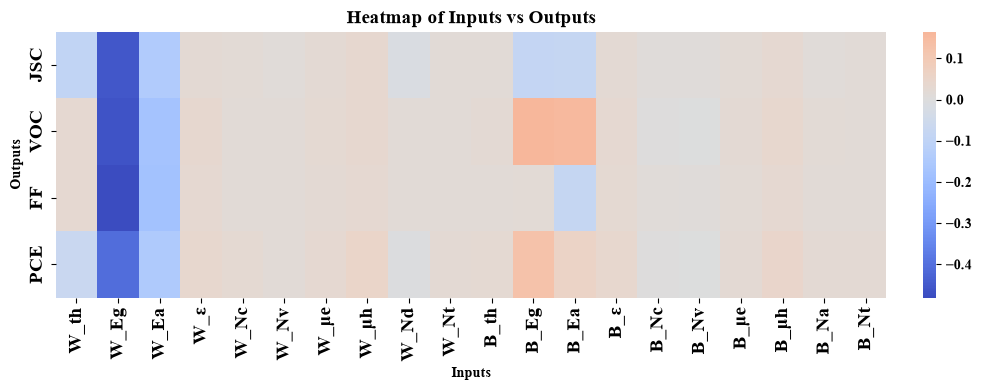

In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df = pd.read_csv("your_file.csv")   # load your data if not already loaded

# 1) Shortcut names (window layer + back layer)
rename_map = {
    # Window layer
    'W_Thickness': 'W_th', 'W_Eg': 'W_Eg', 'W_Ea': 'W_Ea', 'W_Dp': 'W_ε',
    'W_Nc': 'W_Nc', 'W_Nv': 'W_Nv', 'W_Ue': 'W_μe', 'W_Uh': 'W_μh',
    'W_Na': 'W_Nd', 'W_dd': 'W_Nt',
    # Back layer
    'B_Thickness': 'B_th', 'B_Eg': 'B_Eg', 'B_Ea': 'B_Ea', 'B_Dp': 'B_ε',
    'B_Nc': 'B_Nc', 'B_Nv': 'B_Nv', 'B_Ue': 'B_μe', 'B_Uh': 'B_μh',
    'B_Na': 'B_Na', 'B_dd': 'B_Nt',
}
output_map = {'Jsc': 'JSC', 'Voc': 'VOC', 'FF': 'FF', 'PCE': 'PCE'}

# 2) Keep the needed columns, plus 'Structure' for grouping
cols = ['Structure'] + list(rename_map) + list(output_map)
data = df[cols].rename(columns={**rename_map, **output_map})

inputs  = list(rename_map.values())
outputs = ['JSC', 'VOC', 'FF', 'PCE']

# 3) Correlation inside each structure (rows = outputs, cols = inputs)
corr_list = []
for name, g in data.groupby('Structure'):
    c = g[inputs + outputs].corr().loc[outputs, inputs]
    corr_list.append(c.values)
    print(f"{name}: {len(g)} samples")

# 4) Average across structures (NaN-safe, in case a column is constant in one structure)
corr_avg = pd.DataFrame(np.nanmean(np.stack(corr_list), axis=0),
                        index=outputs, columns=inputs)

# 5) Plot
plt.figure(figsize=(10, 4))
ax = sns.heatmap(corr_avg, cmap='coolwarm', center=0, annot=False,
                 cbar=True, cbar_kws={'fraction': 0.046, 'pad': 0.04})

ax.set_title('Heatmap of Inputs vs Outputs', fontsize=14, fontweight='bold')
ax.set_xlabel('Inputs', fontweight='bold')
ax.set_ylabel('Outputs', fontweight='bold')
plt.xticks(rotation=90, fontsize=14, fontweight='bold')
plt.yticks(rotation=90, fontsize=14, fontweight='bold', va='center')

plt.tight_layout()
plt.savefig('correlation_heatmap_structurewise.png', dpi=300, bbox_inches='tight')
plt.show()

# **Train Test Split**

In [42]:
# # Features and target variables
# X = df.drop(['Voc', 'Jsc', 'FF', 'PCE', 'R', 'D*',
#              "Structure"
#              ]
#             , axis = 1)

# y = df[['Voc', 'Jsc', 'FF', 'PCE', 'R', 'D*']]

# # Split the dataset (90% training, 10% testing)
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

# Define y and X structures
y_structures = [ 1,3] 

# Create X and y datasets
y_data = df[df["Structure"].isin(y_structures)].reset_index(drop=True)
X_data = df[~df["Structure"].isin(y_structures)].reset_index(drop=True)

# Drop "Structure" column from features
X = X_data.drop(columns=["Structure"])
y = y_data.drop(columns=["Structure"])


X_train = X.drop(columns=["Voc", "Jsc", "FF", "PCE"]).reset_index(drop=True)
y_train = X[["Voc", "Jsc", "FF", "PCE"]].reset_index(drop=True)

X_test = y.drop(columns=["Voc", "Jsc", "FF", "PCE"]).reset_index(drop=True)
y_test = y[["Voc", "Jsc", "FF", "PCE"]].reset_index(drop=True)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# # ===== APPLY LOG10 TRANSFORMATION TO LARGE NUMBERS (>1e4) =====
# print("\n" + "="*80)
# print("🔧 APPLYING LOG10 TRANSFORMATION TO LARGE NUMBERS (>1e4)")
# print("="*80)

# # Identify columns with max values > 1e4 in numeric columns only
# numeric_cols = X_train.select_dtypes(include=[np.number]).columns
# log_transform_cols = [col for col in numeric_cols if X_train[col].max() > 1e4]

# print(f"\n❌ BEFORE TRANSFORMATION:")
# print(f"   Columns to transform (max > 1e4): {log_transform_cols}")
# for col in log_transform_cols:
#     print(f"   {col}: {X_train[col].min():.2e} to {X_train[col].max():.2e}")

# # Apply log10 transformation to identified columns
# for col in log_transform_cols:
#     X_train[col] = np.log10(X_train[col])
#     X_test[col] = np.log10(X_test[col])
#     X[col] = np.log10(X[col])

# print(f"\n✅ AFTER TRANSFORMATION:")
# for col in log_transform_cols:
#     print(f"   {col}: {X_train[col].min():.2f} to {X_train[col].max():.2f}")

# print(f"\n💡 BENEFITS:")
# print(f"   ✓ Large values normalized to manageable scale")
# print(f"   ✓ Better model performance with normalized features")
# print(f"   ✓ Predictions will be inverse transformed with 10^x")
# print("="*80)

X_train shape: (1400, 32)
X_test shape: (400, 32)
y_train shape: (1400, 4)
y_test shape: (400, 4)


In [43]:
X_test.columns

Index(['Window', 'W_Thickness', 'W_Eg', 'W_Ea', 'W_Dp', 'W_Nc', 'W_Nv', 'W_Ue',
       'W_Uh', 'W_Na', 'W_dd', 'A_Thickness', 'A_Eg', 'A_Ea', 'A_Dp', 'A_Nc',
       'A_Nv', 'A_Ue', 'A_Uh', 'A_Na', 'A_dd', 'BSF', 'B_Thickness', 'B_Eg',
       'B_Ea', 'B_Dp', 'B_Nc', 'B_Nv', 'B_Ue', 'B_Uh', 'B_Na', 'B_dd'],
      dtype='str')

In [44]:
y_test

,Voc,Jsc,FF,PCE
0,1.133306,27.169946,89.0159,27.4097
1,1.133291,27.154931,89.0156,27.3941
2,1.133273,27.137083,89.0154,27.3756
3,1.133254,27.118020,89.0153,27.3558
4,1.133234,27.098420,89.0151,27.3355
...,...,...,...,...
395,1.136959,27.073393,88.6394,27.2844
396,1.136959,27.073393,88.6394,27.2844
397,1.136959,27.073393,88.6394,27.2844
398,1.136959,27.073393,88.6394,27.2844


# <font color="lightgreen"> **Random Forest Regressor (RF)**

In [45]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

print("="*80)
print("🌲 RANDOM FOREST - PER-TARGET OPTIMIZED MODELS")
print("="*80)

# Best hyperparameters for each target from hyperparameter tuning
best_params_per_target = {
    'Voc': {'n_estimators': 200, 'max_depth': 15},
    'Jsc': {'n_estimators': 200, 'max_depth': 15},
    'FF': {'n_estimators': 200, 'max_depth': 15},
    'PCE': {'n_estimators': 200, 'max_depth': 15},
}

# Initialize dictionaries to store models and metrics
best_rf_models = {}
rf_test_predictions = {}
rf_train_predictions = {}
metrics_dict_RF = {}
metrics_dict_RF_train = {}

targets = ['Voc', 'Jsc', 'FF', 'PCE']

# Train individual RF model for each target
for target in targets:
    print(f"\n🔨 Training RandomForest for {target}...")
    params = best_params_per_target[target]
    
    # Initialize and train RF model with target-specific hyperparameters
    rf_model = RandomForestRegressor(
        n_estimators=params['n_estimators'],
        max_depth=params['max_depth'],
        random_state=42,
        n_jobs=-1
    )
    
    y_train_target = y_train[[target]].values.ravel()
    y_test_target = y_test[[target]].values.ravel()
    
    rf_model.fit(X_train, y_train_target)
    best_rf_models[target] = rf_model
    
    # --- Test Predictions ---
    rf_test_pred = rf_model.predict(X_test)
    rf_test_mse = mean_squared_error(y_test_target, rf_test_pred)
    rf_test_rmse = np.sqrt(rf_test_mse)
    rf_test_mae = mean_absolute_error(y_test_target, rf_test_pred)
    rf_test_r2 = r2_score(y_test_target, rf_test_pred)
    
    metrics_dict_RF[target] = {
        'MSE': rf_test_mse,
        'RMSE': rf_test_rmse,
        'MAE': rf_test_mae,
        'R² Score': rf_test_r2
    }
    
    # --- Train Predictions ---
    rf_train_pred = rf_model.predict(X_train)
    rf_train_mse = mean_squared_error(y_train_target, rf_train_pred)
    rf_train_rmse = np.sqrt(rf_train_mse)
    rf_train_mae = mean_absolute_error(y_train_target, rf_train_pred)
    rf_train_r2 = r2_score(y_train_target, rf_train_pred)
    
    metrics_dict_RF_train[target] = {
        'MSE': rf_train_mse,
        'RMSE': rf_train_rmse,
        'MAE': rf_train_mae,
        'R² Score': rf_train_r2
    }
    
    # Store predictions
    rf_test_predictions[target] = rf_test_pred
    rf_train_predictions[target] = rf_train_pred
    
    print(f"   ✅ Test R²: {rf_test_r2:.4f} | Train R²: {rf_train_r2:.4f}")

# Create comprehensive DataFrames
metrics_df_RF = pd.DataFrame(metrics_dict_RF).T
metrics_df_RF_train = pd.DataFrame(metrics_dict_RF_train).T

# Create full prediction DataFrames
rf_y_pred_df = pd.DataFrame(rf_test_predictions).T.T  # Transpose to get columns as targets
rf_y_train_pred_df = pd.DataFrame(rf_train_predictions).T.T

# Ensure correct column order
rf_y_pred_df.columns = targets
rf_y_train_pred_df.columns = targets

print("\n" + "="*80)
print("📊 RANDOM FOREST TEST SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_RF.to_string())

print("\n" + "="*80)
print("📊 RANDOM FOREST TRAIN SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_RF_train.to_string())

print("\n✅ Per-target RandomForest models created and evaluated")

🌲 RANDOM FOREST - PER-TARGET OPTIMIZED MODELS

🔨 Training RandomForest for Voc...
   ✅ Test R²: 0.9650 | Train R²: 0.9852

🔨 Training RandomForest for Jsc...
   ✅ Test R²: 0.9574 | Train R²: 0.9774

🔨 Training RandomForest for FF...
   ✅ Test R²: 0.9594 | Train R²: 0.9841

🔨 Training RandomForest for PCE...
   ✅ Test R²: 0.9373 | Train R²: 0.9693

📊 RANDOM FOREST TEST SET METRICS (PER-TARGET OPTIMIZED)
           MSE      RMSE       MAE  R² Score
Voc   0.001981  0.044509  0.026396  0.965030
Jsc   1.396136  1.181582  0.267729  0.957356
FF   14.128011  3.758725  1.614889  0.959379
PCE   2.168627  1.472626  0.734104  0.937342

📊 RANDOM FOREST TRAIN SET METRICS (PER-TARGET OPTIMIZED)
          MSE      RMSE       MAE  R² Score
Voc  0.000306  0.017490  0.002927  0.985246
Jsc  0.261394  0.511267  0.087183  0.977384
FF   1.959216  1.399720  0.225751  0.984087
PCE  0.402555  0.634473  0.223031  0.969261

✅ Per-target RandomForest models created and evaluated


# <font color="lightgreen"> **Gradient Boosting Regressor (GBR)**

In [46]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

print("="*80)
print("📊 GRADIENT BOOSTING - PER-TARGET OPTIMIZED MODELS")
print("="*80)

# Best hyperparameters for each target from hyperparameter tuning
best_params_per_target_gbr = {
    'Voc': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500},
    'Jsc': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500},
    'FF': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500},
    'PCE': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500},
    # 'R': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500},
    # 'D*': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500}
}

# Initialize dictionaries to store models and metrics
best_gbr_models = {}
gbr_test_predictions = {}
gbr_train_predictions = {}
metrics_dict_GBR = {}
metrics_dict_GBR_train = {}

targets = ['Voc', 'Jsc', 'FF', 'PCE']

# Train individual GBR model for each target
for target in targets:
    print(f"\n🔨 Training GradientBoosting for {target}...")
    params = best_params_per_target_gbr[target]
    
    # Initialize and train GBR model with target-specific hyperparameters
    gbr_model = GradientBoostingRegressor(
        learning_rate=params['learning_rate'],
        max_depth=params['max_depth'],
        n_estimators=params['n_estimators'],
        random_state=42
    )
    
    y_train_target = y_train[[target]].values.ravel()
    y_test_target = y_test[[target]].values.ravel()
    
    gbr_model.fit(X_train, y_train_target)
    best_gbr_models[target] = gbr_model
    
    # --- Test Predictions ---
    gbr_test_pred = gbr_model.predict(X_test)
    gbr_test_mse = mean_squared_error(y_test_target, gbr_test_pred)
    gbr_test_rmse = np.sqrt(gbr_test_mse)
    gbr_test_mae = mean_absolute_error(y_test_target, gbr_test_pred)
    gbr_test_r2 = r2_score(y_test_target, gbr_test_pred)
    
    metrics_dict_GBR[target] = {
        'MSE': gbr_test_mse,
        'RMSE': gbr_test_rmse,
        'MAE': gbr_test_mae,
        'R² Score': gbr_test_r2
    }
    
    # --- Train Predictions ---
    gbr_train_pred = gbr_model.predict(X_train)
    gbr_train_mse = mean_squared_error(y_train_target, gbr_train_pred)
    gbr_train_rmse = np.sqrt(gbr_train_mse)
    gbr_train_mae = mean_absolute_error(y_train_target, gbr_train_pred)
    gbr_train_r2 = r2_score(y_train_target, gbr_train_pred)
    
    metrics_dict_GBR_train[target] = {
        'MSE': gbr_train_mse,
        'RMSE': gbr_train_rmse,
        'MAE': gbr_train_mae,
        'R² Score': gbr_train_r2
    }
    
    # Store predictions
    gbr_test_predictions[target] = gbr_test_pred
    gbr_train_predictions[target] = gbr_train_pred
    
    print(f"   ✅ Test R²: {gbr_test_r2:.4f} | Train R²: {gbr_train_r2:.4f}")

# Create comprehensive DataFrames
metrics_df_GBR = pd.DataFrame(metrics_dict_GBR).T
metrics_df_GBR_train = pd.DataFrame(metrics_dict_GBR_train).T

# Create full prediction DataFrames
gbr_y_pred_df = pd.DataFrame(gbr_test_predictions).T.T
gbr_y_train_pred_df = pd.DataFrame(gbr_train_predictions).T.T

# Ensure correct column order
gbr_y_pred_df.columns = targets
gbr_y_train_pred_df.columns = targets

print("\n" + "="*80)
print("📊 GRADIENT BOOSTING TEST SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_GBR.to_string())

print("\n" + "="*80)
print("📊 GRADIENT BOOSTING TRAIN SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_GBR_train.to_string())

print("\n✅ Per-target GradientBoosting models created and evaluated")

📊 GRADIENT BOOSTING - PER-TARGET OPTIMIZED MODELS

🔨 Training GradientBoosting for Voc...
   ✅ Test R²: 0.9965 | Train R²: 0.9996

🔨 Training GradientBoosting for Jsc...
   ✅ Test R²: 0.9974 | Train R²: 0.9997

🔨 Training GradientBoosting for FF...
   ✅ Test R²: 0.9930 | Train R²: 0.9999

🔨 Training GradientBoosting for PCE...
   ✅ Test R²: 0.9932 | Train R²: 0.9982

📊 GRADIENT BOOSTING TEST SET METRICS (PER-TARGET OPTIMIZED)
          MSE      RMSE       MAE  R² Score
Voc  0.000199  0.014109  0.009827  0.996486
Jsc  0.085039  0.291615  0.177639  0.997403
FF   2.418357  1.555107  0.268712  0.993047
PCE  0.236107  0.485909  0.291434  0.993178

📊 GRADIENT BOOSTING TRAIN SET METRICS (PER-TARGET OPTIMIZED)
          MSE      RMSE       MAE  R² Score
Voc  0.000008  0.002867  0.001026  0.999604
Jsc  0.003041  0.055142  0.026048  0.999737
FF   0.017734  0.133168  0.048870  0.999856
PCE  0.024154  0.155415  0.074608  0.998156

✅ Per-target GradientBoosting models created and evaluated


# <font color="lightgreen"> **Linear Regression**

In [47]:
# from sklearn.preprocessing import MinMaxScaler, StandardScaler

# scaler = StandardScaler()
# x_train = scaler.fit_transform(X_train)
# x_test = scaler.transform(X_test)  # Use transform, not fit_transform

# scaler_y = StandardScaler()
# y_train_scaled = scaler_y.fit_transform(y_train)
# y_test_scaled = scaler_y.transform(y_test)

In [48]:
# Train the model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
lr_y_pred = lr.predict(X_test)

# Convert predictions to DataFrame
lr_y_pred_df = pd.DataFrame(lr_y_pred, columns=['Voc', 'Jsc', 'FF', 'PCE'])

# Evaluation on scaled targets
lr_mse = mean_squared_error(y_test, lr_y_pred_df, multioutput='raw_values')
lr_rmse = np.sqrt(lr_mse)
lr_mae = mean_absolute_error(y_test, lr_y_pred_df, multioutput='raw_values')
lr_r2 = r2_score(y_test, lr_y_pred_df, multioutput='raw_values')

# Print metrics
metrics_df_lr = pd.DataFrame({'MSE': lr_mse, 'RMSE': lr_rmse, 'MAE': lr_mae, 'R2 Score': lr_r2},
                           index=['Voc', 'Jsc', 'FF', 'PCE'])
print("Linear Regression Test Metrics (Scaled):\n", metrics_df_lr)

# Also show train metrics
lr_y_train_pred = lr.predict(X_train)
lr_y_train_pred_df = pd.DataFrame(lr_y_train_pred, columns=['Voc', 'Jsc', 'FF', 'PCE'])

lr_train_mse = mean_squared_error(y_train, lr_y_train_pred_df, multioutput='raw_values')
lr_train_rmse = np.sqrt(lr_train_mse)
lr_train_mae = mean_absolute_error(y_train, lr_y_train_pred_df, multioutput='raw_values')
lr_train_r2 = r2_score(y_train, lr_y_train_pred_df, multioutput='raw_values')

metrics_df_lr_train = pd.DataFrame({'MSE': lr_train_mse, 'RMSE': lr_train_rmse, 'MAE': lr_train_mae, 'R2 Score': lr_train_r2}, index=['Voc', 'Jsc', 'FF', 'PCE'])

print("\nLinear Regression Train Metrics (Scaled):\n", metrics_df_lr_train)

Linear Regression Test Metrics (Scaled):
             MSE       RMSE       MAE  R2 Score
Voc    0.057377   0.239534  0.084110 -0.012833
Jsc   32.921532   5.737729  2.006749 -0.005554
FF   353.733807  18.807812  6.082179 -0.017064
PCE   34.670037   5.888127  2.514630 -0.001722

Linear Regression Train Metrics (Scaled):
             MSE       RMSE       MAE  R2 Score
Voc    0.020676   0.143793  0.048641  0.002725
Jsc   11.539636   3.397004  1.001703  0.001566
FF   122.876034  11.084946  3.247493  0.002003
PCE   13.059267   3.613761  1.416395  0.002796


# <font color="lightgreen">**DT regressor**

In [49]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

print("="*80)
print("🌳 DECISION TREE - PER-TARGET OPTIMIZED MODELS")
print("="*80)

# Best hyperparameters for each target from hyperparameter tuning
best_params_per_target_dt = {
    'Voc': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2},
    'Jsc': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2},
    'FF': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2},
    'PCE': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2},
    # 'R': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2},
    # 'D*': {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2}
}

# Initialize dictionaries to store models and metrics
best_dt_models = {}
dt_test_predictions = {}
dt_train_predictions = {}
metrics_dict_DT = {}
metrics_dict_DT_train = {}

targets = ['Voc', 'Jsc', 'FF', 'PCE']

# Train individual DT model for each target
for target in targets:
    print(f"\n🔨 Training DecisionTree for {target}...")
    params = best_params_per_target_dt[target]
    
    # Initialize and train DT model with target-specific hyperparameters
    dt_model = DecisionTreeRegressor(
        max_depth=params['max_depth'],
        min_samples_leaf=params['min_samples_leaf'],
        min_samples_split=params['min_samples_split'],
        random_state=42
    )
    
    y_train_target = y_train[[target]].values.ravel()
    y_test_target = y_test[[target]].values.ravel()
    
    dt_model.fit(X_train, y_train_target)
    best_dt_models[target] = dt_model
    
    # --- Test Predictions ---
    dt_test_pred = dt_model.predict(X_test)
    dt_test_mse = mean_squared_error(y_test_target, dt_test_pred)
    dt_test_rmse = np.sqrt(dt_test_mse)
    dt_test_mae = mean_absolute_error(y_test_target, dt_test_pred)
    dt_test_r2 = r2_score(y_test_target, dt_test_pred)
    
    metrics_dict_DT[target] = {
        'MSE': dt_test_mse,
        'RMSE': dt_test_rmse,
        'MAE': dt_test_mae,
        'R² Score': dt_test_r2
    }
    
    # --- Train Predictions ---
    dt_train_pred = dt_model.predict(X_train)
    dt_train_mse = mean_squared_error(y_train_target, dt_train_pred)
    dt_train_rmse = np.sqrt(dt_train_mse)
    dt_train_mae = mean_absolute_error(y_train_target, dt_train_pred)
    dt_train_r2 = r2_score(y_train_target, dt_train_pred)
    
    metrics_dict_DT_train[target] = {
        'MSE': dt_train_mse,
        'RMSE': dt_train_rmse,
        'MAE': dt_train_mae,
        'R² Score': dt_train_r2
    }
    
    # Store predictions
    dt_test_predictions[target] = dt_test_pred
    dt_train_predictions[target] = dt_train_pred
    
    print(f"   ✅ Test R²: {dt_test_r2:.4f} | Train R²: {dt_train_r2:.4f}")

# Create comprehensive DataFrames
metrics_df_DT = pd.DataFrame(metrics_dict_DT).T
metrics_df_DT_train = pd.DataFrame(metrics_dict_DT_train).T

# Create full prediction DataFrames
dt_y_pred_df = pd.DataFrame(dt_test_predictions).T.T
dt_y_train_pred_df = pd.DataFrame(dt_train_predictions).T.T

# Ensure correct column order
dt_y_pred_df.columns = targets
dt_y_train_pred_df.columns = targets

print("\n" + "="*80)
print("📊 DECISION TREE TEST SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_DT.to_string())

print("\n" + "="*80)
print("📊 DECISION TREE TRAIN SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_DT_train.to_string())

print("\n✅ Per-target DecisionTree models created and evaluated")

🌳 DECISION TREE - PER-TARGET OPTIMIZED MODELS

🔨 Training DecisionTree for Voc...
   ✅ Test R²: 0.8949 | Train R²: 0.8952

🔨 Training DecisionTree for Jsc...
   ✅ Test R²: 0.5729 | Train R²: 0.7629

🔨 Training DecisionTree for FF...
   ✅ Test R²: 0.8746 | Train R²: 0.8907

🔨 Training DecisionTree for PCE...
   ✅ Test R²: 0.6252 | Train R²: 0.7778

📊 DECISION TREE TEST SET METRICS (PER-TARGET OPTIMIZED)
           MSE      RMSE       MAE  R² Score
Voc   0.005951  0.077143  0.038533  0.894949
Jsc  13.984226  3.739549  0.638941  0.572866
FF   43.619126  6.604478  1.712160  0.874585
PCE  12.971220  3.601558  1.210841  0.625222

📊 DECISION TREE TRAIN SET METRICS (PER-TARGET OPTIMIZED)
           MSE      RMSE       MAE  R² Score
Voc   0.002173  0.046613  0.007411  0.895202
Jsc   2.740101  1.655325  0.293280  0.762921
FF   13.453118  3.667849  0.463295  0.890734
PCE   2.910286  1.705956  0.468766  0.777771

✅ Per-target DecisionTree models created and evaluated


# <font color="lightgreen"> **XGB regressor**

In [50]:
print("="*80)
print("⚡ XGBOOST - PER-TARGET OPTIMIZED MODELS")
print("="*80)

# Best hyperparameters for each target from hyperparameter tuning
best_params_per_target_xgb = {
    'Voc': {  'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 1000},
    'Jsc': {  'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 1000},
    'FF': {   'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 1000},
    'PCE': {  'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 1000},
}

# Initialize dictionaries to store models and metrics
best_xgb_models = {}
xgb_test_predictions = {}
xgb_train_predictions = {}
metrics_dict_XGB = {}
metrics_dict_XGB_train = {}

targets = ['Voc', 'Jsc', 'FF', 'PCE']

# Convert to numpy arrays to avoid pandas compatibility issues
X_train_np = X_train.values
X_test_np = X_test.values

# Train individual XGB model for each target
for target in targets:
    print(f"\n🔨 Training XGBoost for {target}...")
    params = best_params_per_target_xgb[target]
    
    # Initialize and train XGB model with target-specific hyperparameters
    xgb_model = XGBRegressor(
        # colsample_bytree=params['colsample_bytree'],
        learning_rate=params['learning_rate'],
        max_depth=params['max_depth'],
        n_estimators=params['n_estimators'],
        # subsample=params['subsample'],
        random_state=42
    )
    
    y_train_target = y_train[[target]].values.ravel()
    y_test_target = y_test[[target]].values.ravel()
    
    xgb_model.fit(X_train_np, y_train_target)
    best_xgb_models[target] = xgb_model
    
    # --- Test Predictions ---
    xgb_test_pred = xgb_model.predict(X_test_np)
    xgb_test_mse = mean_squared_error(y_test_target, xgb_test_pred)
    xgb_test_rmse = np.sqrt(xgb_test_mse)
    xgb_test_mae = mean_absolute_error(y_test_target, xgb_test_pred)
    xgb_test_r2 = r2_score(y_test_target, xgb_test_pred)
    
    metrics_dict_XGB[target] = {
        'MSE': xgb_test_mse,
        'RMSE': xgb_test_rmse,
        'MAE': xgb_test_mae,
        'R² Score': xgb_test_r2
    }
    
    # --- Train Predictions ---
    xgb_train_pred = xgb_model.predict(X_train_np)
    xgb_train_mse = mean_squared_error(y_train_target, xgb_train_pred)
    xgb_train_rmse = np.sqrt(xgb_train_mse)
    xgb_train_mae = mean_absolute_error(y_train_target, xgb_train_pred)
    xgb_train_r2 = r2_score(y_train_target, xgb_train_pred)
    
    metrics_dict_XGB_train[target] = {
        'MSE': xgb_train_mse,
        'RMSE': xgb_train_rmse,
        'MAE': xgb_train_mae,
        'R² Score': xgb_train_r2
    }
    
    # Store predictions
    xgb_test_predictions[target] = xgb_test_pred
    xgb_train_predictions[target] = xgb_train_pred
    
    print(f"   ✅ Test R²: {xgb_test_r2:.4f} | Train R²: {xgb_train_r2:.4f}")

# Create comprehensive DataFrames
metrics_df_XGB = pd.DataFrame(metrics_dict_XGB).T
metrics_train_df_XGB = pd.DataFrame(metrics_dict_XGB_train).T

# Create full prediction DataFrames
XGB_y_pred_df = pd.DataFrame(xgb_test_predictions).T.T
XGB_y_train_pred_df = pd.DataFrame(xgb_train_predictions).T.T

# Ensure correct column order
XGB_y_pred_df.columns = targets
XGB_y_train_pred_df.columns = targets

print("\n" + "="*80)
print("📊 XGBOOST TEST SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_df_XGB.to_string())

print("\n" + "="*80)
print("📊 XGBOOST TRAIN SET METRICS (PER-TARGET OPTIMIZED)")
print("="*80)
print(metrics_train_df_XGB.to_string())

print("\n✅ Per-target XGBoost models created and evaluated")

⚡ XGBOOST - PER-TARGET OPTIMIZED MODELS

🔨 Training XGBoost for Voc...
   ✅ Test R²: 0.9950 | Train R²: 0.9997

🔨 Training XGBoost for Jsc...
   ✅ Test R²: 0.9983 | Train R²: 0.9999

🔨 Training XGBoost for FF...
   ✅ Test R²: 0.9896 | Train R²: 1.0000

🔨 Training XGBoost for PCE...
   ✅ Test R²: 0.9945 | Train R²: 0.9993

📊 XGBOOST TEST SET METRICS (PER-TARGET OPTIMIZED)
          MSE      RMSE       MAE  R² Score
Voc  0.000281  0.016761  0.013227  0.995041
Jsc  0.056780  0.238285  0.078972  0.998266
FF   3.612796  1.900736  0.481058  0.989612
PCE  0.190237  0.436161  0.205361  0.994503

📊 XGBOOST TRAIN SET METRICS (PER-TARGET OPTIMIZED)
          MSE      RMSE       MAE  R² Score
Voc  0.000006  0.002475  0.000990  0.999705
Jsc  0.001394  0.037338  0.015162  0.999879
FF   0.004192  0.064745  0.029370  0.999966
PCE  0.009038  0.095068  0.044452  0.999310

✅ Per-target XGBoost models created and evaluated


In [51]:
import os
import joblib

os.makedirs("saved_models", exist_ok=True)

pce_model = best_xgb_models['PCE']

# Option 1 (recommended): XGBoost's native format, stable across versions
pce_model.save_model("saved_models/xgb_pce.json")

# LightGBM

In [52]:
# from lightgbm import LGBMRegressor
# from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# import numpy as np
# import pandas as pd

# print("="*80)
# print("💡 LIGHTGBM - PER-TARGET OPTIMIZED MODELS")
# print("="*80)

# # Best hyperparameters for each target from hyperparameter tuning
# best_params_per_target_lgb = {
#     'Voc': {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500},
#     'Jsc': {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500},
#     'FF': {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500},
#     'PCE': {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500},
#     'R': {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500},
#     'D*': {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 500}
# }

# # Initialize dictionaries to store models and metrics
# best_lgb_models = {}
# lgb_test_predictions = {}
# lgb_train_predictions = {}
# metrics_dict_LGB = {}
# metrics_dict_LGB_train = {}

# targets = ['Voc', 'Jsc', 'FF', 'PCE', 'R', 'D*']

# # Train individual LGB model for each target
# for target in targets:
#     print(f"\n🔨 Training LightGBM for {target}...")
#     params = best_params_per_target_lgb[target]
    
#     # Initialize and train LGB model with target-specific hyperparameters
#     lgb_model = LGBMRegressor(
#         learning_rate=params['learning_rate'],
#         max_depth=params['max_depth'],
#         n_estimators=params['n_estimators'],
#         # num_leaves=params['num_leaves'],
#         random_state=42,
#         verbose=-1
#     )
    
#     y_train_target = y_train[[target]].values.ravel()
#     y_test_target = y_test[[target]].values.ravel()
    
#     lgb_model.fit(X_train, y_train_target)
#     best_lgb_models[target] = lgb_model
    
#     # --- Test Predictions ---
#     lgb_test_pred = lgb_model.predict(X_test)
#     lgb_test_mse = mean_squared_error(y_test_target, lgb_test_pred)
#     lgb_test_rmse = np.sqrt(lgb_test_mse)
#     lgb_test_mae = mean_absolute_error(y_test_target, lgb_test_pred)
#     lgb_test_r2 = r2_score(y_test_target, lgb_test_pred)
    
#     metrics_dict_LGB[target] = {
#         'MSE': lgb_test_mse,
#         'RMSE': lgb_test_rmse,
#         'MAE': lgb_test_mae,
#         'R² Score': lgb_test_r2
#     }
    
#     # --- Train Predictions ---
#     lgb_train_pred = lgb_model.predict(X_train)
#     lgb_train_mse = mean_squared_error(y_train_target, lgb_train_pred)
#     lgb_train_rmse = np.sqrt(lgb_train_mse)
#     lgb_train_mae = mean_absolute_error(y_train_target, lgb_train_pred)
#     lgb_train_r2 = r2_score(y_train_target, lgb_train_pred)
    
#     metrics_dict_LGB_train[target] = {
#         'MSE': lgb_train_mse,
#         'RMSE': lgb_train_rmse,
#         'MAE': lgb_train_mae,
#         'R² Score': lgb_train_r2
#     }
    
#     # Store predictions
#     lgb_test_predictions[target] = lgb_test_pred
#     lgb_train_predictions[target] = lgb_train_pred
    
#     print(f"   ✅ Test R²: {lgb_test_r2:.4f} | Train R²: {lgb_train_r2:.4f}")

# # Create comprehensive DataFrames
# metrics_df_LGB = pd.DataFrame(metrics_dict_LGB).T
# metrics_df_LGB_train = pd.DataFrame(metrics_dict_LGB_train).T

# # Create full prediction DataFrames
# lgb_y_pred_df = pd.DataFrame(lgb_test_predictions).T.T
# lgb_y_train_pred_df = pd.DataFrame(lgb_train_predictions).T.T

# # Ensure correct column order
# lgb_y_pred_df.columns = targets
# lgb_y_train_pred_df.columns = targets

# print("\n" + "="*80)
# print("📊 LIGHTGBM TEST SET METRICS (PER-TARGET OPTIMIZED)")
# print("="*80)
# print(metrics_df_LGB.to_string())

# print("\n" + "="*80)
# print("📊 LIGHTGBM TRAIN SET METRICS (PER-TARGET OPTIMIZED)")
# print("="*80)
# print(metrics_df_LGB_train.to_string())

# print("\n✅ Per-target LightGBM models created and evaluated")

# MLP

Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.2443 - mae: 0.4529 - val_loss: 1.5310 - val_mae: 0.3697 - learning_rate: 0.0010
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0846 - mae: 0.3717 - val_loss: 1.4541 - val_mae: 0.3561 - learning_rate: 0.0010
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0202 - mae: 0.3514 - val_loss: 1.3503 - val_mae: 0.3545 - learning_rate: 0.0010
Epoch 4/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9752 - mae: 0.3488 - val_loss: 1.2832 - val_mae: 0.3249 - learning_rate: 0.0010
Epoch 5/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9194 - mae: 0.3380 - val_loss: 1.1356 - val_mae: 0.3166 - learning_rate: 0.0010
Epoch 6/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8556 - mae: 0.3252 - val_loss: 0.9922 - val_mae: 0.3029 - learning_rate: 0.0010
Epoch 7/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7526 - mae: 0.3216 - val_loss: 0.8398 - val_mae: 0.2842 - learning_rate: 0.0010
Epoch 8/100
8

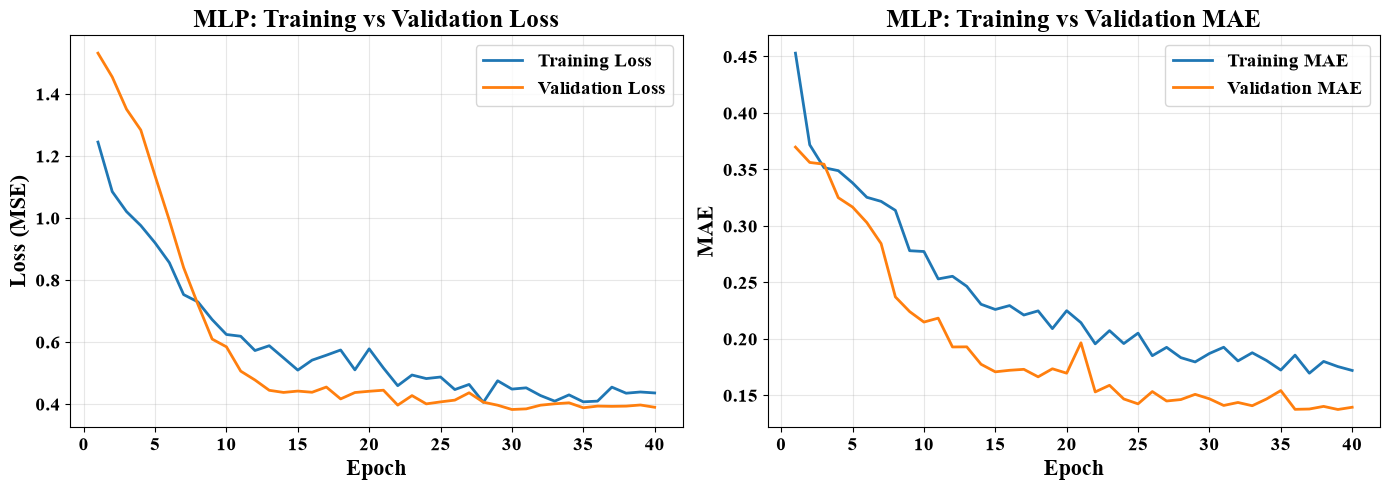

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

# -----------------------------
# 1. Feature Scaling (X and y)
# -----------------------------
scaler_mlp_X = StandardScaler()
scaler_mlp_y = StandardScaler()

X_train_mlp = scaler_mlp_X.fit_transform(X_train)
X_test_mlp = scaler_mlp_X.transform(X_test)

y_train_mlp = scaler_mlp_y.fit_transform(y_train)
y_test_mlp = scaler_mlp_y.transform(y_test)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_mlp, y_train_mlp, test_size=0.2, random_state=42
)

# -----------------------------
# 2. Build Improved MLP Model
# -----------------------------
mlp_model = Sequential([
    Input(shape=(X_train_mlp.shape[1],)),  # ✅ fixed warning

    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),

    Dense(y_train_mlp.shape[1])
])

# -----------------------------
# 3. Compile Model
# -----------------------------
mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# -----------------------------
# 4. Callbacks
# -----------------------------
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

# -----------------------------
# 5. Train Model
# -----------------------------
history = mlp_model.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

print(f"✅ MLP trained for {len(history.history['loss'])} epochs")

# -----------------------------
# 6. Predictions
# -----------------------------
mlp_y_train_pred_scaled = mlp_model.predict(X_train_mlp, verbose=0)
mlp_y_test_pred_scaled = mlp_model.predict(X_test_mlp, verbose=0)

# Inverse transform
mlp_y_train_pred = scaler_mlp_y.inverse_transform(mlp_y_train_pred_scaled)
mlp_y_test_pred = scaler_mlp_y.inverse_transform(mlp_y_test_pred_scaled)

# Convert to DataFrame
labels = ['Voc', 'Jsc', 'FF', 'PCE']

mlp_y_train_pred_df = pd.DataFrame(mlp_y_train_pred, columns=labels)
mlp_y_test_pred_df = pd.DataFrame(mlp_y_test_pred, columns=labels)

# -----------------------------
# 7. Metrics Calculation
# -----------------------------
mlp_mse = mean_squared_error(y_test, mlp_y_test_pred_df, multioutput='raw_values')
mlp_rmse = np.sqrt(mlp_mse)
mlp_mae = mean_absolute_error(y_test, mlp_y_test_pred_df, multioutput='raw_values')
mlp_r2 = r2_score(y_test, mlp_y_test_pred_df, multioutput='raw_values')

metrics_df_MLP = pd.DataFrame({
    'MSE': mlp_mse,
    'RMSE': mlp_rmse,
    'MAE': mlp_mae,
    'R² Score': mlp_r2
}, index=labels)

# Train metrics
mlp_train_mse = mean_squared_error(y_train, mlp_y_train_pred_df, multioutput='raw_values')
mlp_train_rmse = np.sqrt(mlp_train_mse)
mlp_train_mae = mean_absolute_error(y_train, mlp_y_train_pred_df, multioutput='raw_values')
mlp_train_r2 = r2_score(y_train, mlp_y_train_pred_df, multioutput='raw_values')

metrics_df_MLP_train = pd.DataFrame({
    'MSE': mlp_train_mse,
    'RMSE': mlp_train_rmse,
    'MAE': mlp_train_mae,
    'R² Score': mlp_train_r2
}, index=labels)

# -----------------------------
# 8. Print Results
# -----------------------------
print("\nMLP Test Metrics:\n", metrics_df_MLP)
print("\nMLP Train Metrics:\n", metrics_df_MLP_train)

# -----------------------------
# 9. Plot Training Curves
# -----------------------------
plt.rcParams['font.family'] = 'Times New Roman'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history.history['loss']) + 1)

axes[0].plot(epochs_range, history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(epochs_range, history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=16)
axes[0].set_ylabel('Loss (MSE)', fontsize=16)
axes[0].set_title('MLP: Training vs Validation Loss', fontsize=18)
axes[0].legend(fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis='both', which='major', labelsize=14)

axes[1].plot(epochs_range, history.history['mae'], label='Training MAE', linewidth=2)
axes[1].plot(epochs_range, history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=16)
axes[1].set_ylabel('MAE', fontsize=16)
axes[1].set_title('MLP: Training vs Validation MAE', fontsize=18)
axes[1].legend(fontsize=14)
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
# plt.savefig('improved_mlp_curves.png', dpi=300, bbox_inches='tight')
plt.show()

# print("✅ Improved MLP curves saved as 'improved_mlp_curves.png'")

In [54]:
import matplotlib.pyplot as plt
# Set global font sizes for labels, ticks, and titles
import matplotlib as mpl

# Set global font family to Times New Roman
mpl.rcParams['font.family'] = 'Times New Roman'

mpl.rcParams['axes.titlesize'] = 16     # Title font size
mpl.rcParams['axes.labelsize'] = 16    # X and Y axis labels
mpl.rcParams['xtick.labelsize'] = 14    # X-axis tick labels
mpl.rcParams['ytick.labelsize'] = 14    # Y-axis tick labels
mpl.rcParams['legend.fontsize'] = 12    # Legend font size (if any)

# Set global font weight to bold and family to Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'

# Set math text to also use Times New Roman for bold formatting
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'


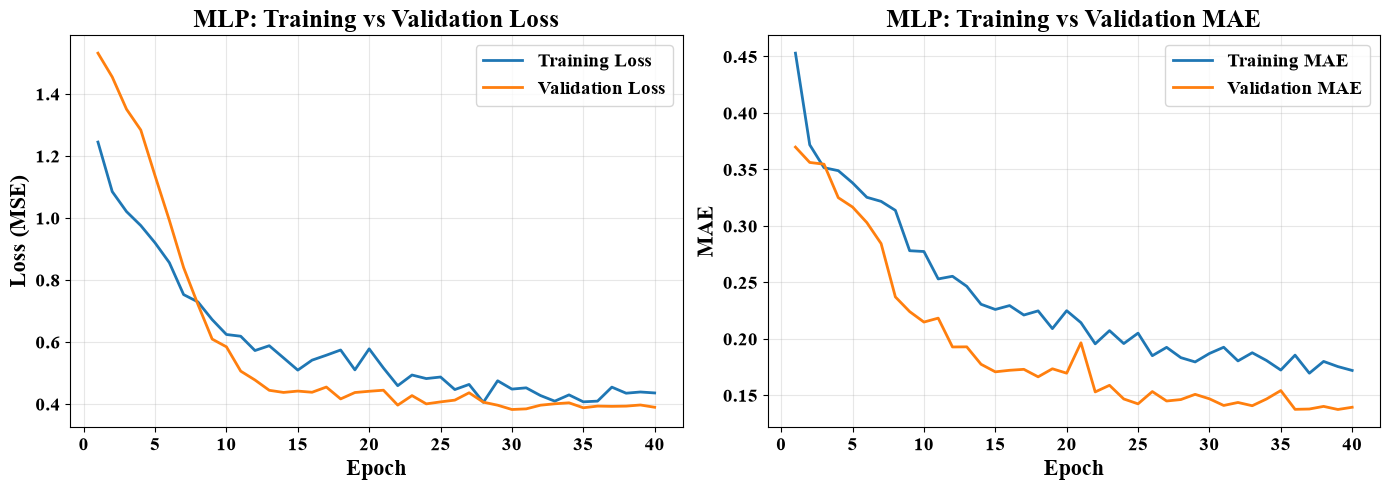

In [55]:
# -----------------------------
# 9. Plot Training Curves
# -----------------------------
plt.rcParams['font.family'] = 'Times New Roman'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history.history['loss']) + 1)

axes[0].plot(epochs_range, history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(epochs_range, history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=16)
axes[0].set_ylabel('Loss (MSE)', fontsize=16)
axes[0].set_title('MLP: Training vs Validation Loss', fontsize=18)
axes[0].legend(fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis='both', which='major', labelsize=14)

axes[1].plot(epochs_range, history.history['mae'], label='Training MAE', linewidth=2)
axes[1].plot(epochs_range, history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=16)
axes[1].set_ylabel('MAE', fontsize=16)
axes[1].set_title('MLP: Training vs Validation MAE', fontsize=18)
axes[1].legend(fontsize=14)
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
# plt.savefig('improved_mlp_curves.png', dpi=300, bbox_inches='tight')
plt.show()

# print("✅ Improved MLP curves saved as 'improved_mlp_curves.png'")

# Tabnet

In [56]:
# from pytorch_tabnet.tab_model import TabNetRegressor
# import numpy as np

# # Scale features for TabNet
# scaler_tabnet = StandardScaler()
# X_train_tabnet = scaler_tabnet.fit_transform(X_train)
# X_test_tabnet = scaler_tabnet.transform(X_test)

# # TabNet models for each target (multi-output)
# tabnet_models = {}
# tabnet_predictions_train = {}
# tabnet_predictions_test = {}
# tabnet_results = []

# targets = ['Voc', 'Jsc', 'FF', 'PCE', 'R', 'D*']

# print("🔹 Training TabNet for multi-output regression...\n")

# for target in targets:
#     print(f"Training TabNet for {target}...")
    
#     tabnet_model = TabNetRegressor(
#         n_d=64,  # width of shared layers
#         n_a=64,  # width of decision layers
#         n_steps=3,  # number of decision steps
#         gamma=1.5,  # relaxation parameter
#         lambda_sparse=1e-3,
#         momentum=0.9,
#         mask_type='sparsemax',
#         verbose=0
#     )
    
#     # Train TabNet
#     tabnet_model.fit(
#         X_train_tabnet, y_train[[target]].values,
#         eval_set=[(X_test_tabnet, y_test[[target]].values)],
#         max_epochs=200,
#         patience=20,
#         batch_size=64,
#         virtual_batch_size=128
#     )
    
#     tabnet_models[target] = tabnet_model
    
#     # Predictions
#     tabnet_predictions_train[target] = tabnet_model.predict(X_train_tabnet)
#     tabnet_predictions_test[target] = tabnet_model.predict(X_test_tabnet)

# # Combine predictions into DataFrames
# tabnet_y_train_pred = np.concatenate([tabnet_predictions_train[t] for t in targets], axis=1)
# tabnet_y_test_pred = np.concatenate([tabnet_predictions_test[t] for t in targets], axis=1)

# tabnet_y_train_pred_df = pd.DataFrame(tabnet_y_train_pred, columns=targets)
# tabnet_y_test_pred_df = pd.DataFrame(tabnet_y_test_pred, columns=targets)

# # --- Test Evaluation ---
# tabnet_mse = mean_squared_error(y_test, tabnet_y_test_pred_df, multioutput='raw_values')
# tabnet_rmse = np.sqrt(tabnet_mse)
# tabnet_mae = mean_absolute_error(y_test, tabnet_y_test_pred_df, multioutput='raw_values')
# tabnet_r2 = r2_score(y_test, tabnet_y_test_pred_df, multioutput='raw_values')

# metrics_df_TabNet = pd.DataFrame({'MSE': tabnet_mse, 'RMSE': tabnet_rmse, 'MAE': tabnet_mae, 'R² Score': tabnet_r2},
#                              index=targets)

# # --- Train Evaluation ---
# tabnet_train_mse = mean_squared_error(y_train, tabnet_y_train_pred_df, multioutput='raw_values')
# tabnet_train_rmse = np.sqrt(tabnet_train_mse)
# tabnet_train_mae = mean_absolute_error(y_train, tabnet_y_train_pred_df, multioutput='raw_values')
# tabnet_train_r2 = r2_score(y_train, tabnet_y_train_pred_df, multioutput='raw_values')

# metrics_df_TabNet_train = pd.DataFrame({'MSE': tabnet_train_mse, 'RMSE': tabnet_train_rmse, 'MAE': tabnet_train_mae, 'R² Score': tabnet_train_r2},
#                                   index=targets)

# print("\n✅ TabNet Test Metrics:\n", metrics_df_TabNet)
# print("\n✅ TabNet Train Metrics:\n", metrics_df_TabNet_train)

# Best Models

In [65]:
# Dictionary to hold the R2 score DataFrames for each model
r2_summary_dict = {
    'Linear Regression': metrics_df_lr['R2 Score'],
    'Random Forest': metrics_df_RF['R² Score'],
    'Gradient Boosting': metrics_df_GBR['R² Score'],
    'XGBoost': metrics_df_XGB['R² Score'],
    # 'LightGBM': metrics_df_LGB['R² Score'],
    'Decision Tree': metrics_df_DT['R² Score'],
    'MLP': metrics_df_MLP['R² Score'],
    # 'TabNet': metrics_df_TabNet['R² Score'] 
}

# Create a combined summary DataFrame for R2 scores on the Test set
r2_summary_df = pd.DataFrame(r2_summary_dict)

print("Best model based on Test R2 score for each output target:")
print("-" * 55)

# For each target (index of the dataframe), find the model with the maximum R2 score
for target in r2_summary_df.index:
    best_model = r2_summary_df.loc[target].idxmax()
    best_r2 = r2_summary_df.loc[target].max()
    print(f"Target '{target}': {best_model} (R² = {best_r2:.4f})")

Best model based on Test R2 score for each output target:
-------------------------------------------------------
Target 'Voc': Gradient Boosting (R² = 0.9965)
Target 'Jsc': XGBoost (R² = 0.9983)
Target 'FF': Gradient Boosting (R² = 0.9930)
Target 'PCE': XGBoost (R² = 0.9945)


# Making DOCX Table for all models

In [58]:
import pandas as pd

# Dictionary of all 8 models with (test_metrics, train_metrics)
models = {
    'RF': (metrics_df_RF, metrics_df_RF_train),
    'GB': (metrics_df_GBR, metrics_df_GBR_train),
    'LR': (metrics_df_lr, metrics_df_lr_train),
    'DT': (metrics_df_DT, metrics_df_DT_train),
    'XGB': (metrics_df_XGB, metrics_train_df_XGB),
    # 'LGB': (metrics_df_LGB, metrics_df_LGB_train),
    'MLP': (metrics_df_MLP, metrics_df_MLP_train),
    # 'TabNet': (metrics_df_TabNet, metrics_df_TabNet_train)
}

targets = ['Voc', 'Jsc', 'FF', 'PCE']
metrics = ['MAE', 'RMSE', 'R² Score']

# ========== TEST SET TABLE ==========
print("\n" + "="*120)
print("📊 ALL MODELS - TEST SET PERFORMANCE METRICS")
print("="*120)

test_rows = []
for model_name, (test_df, train_df) in models.items():
    for idx, metric in enumerate(metrics):
        col_name = metric
        row = {'Model': model_name, 'Metric': metric}
        
        for target in targets:
            try:
                val = round(test_df.loc[target, col_name], 4)
            except:
                val = '-'
            row[target] = val
        
        test_rows.append(row)

test_table_df = pd.DataFrame(test_rows)
test_table_df = test_table_df[['Model', 'Metric'] + targets]

print("\n")
print(test_table_df.to_string(index=False))

# ========== TRAIN SET TABLE ==========
print("\n" + "="*120)
print("📊 ALL MODELS - TRAIN SET PERFORMANCE METRICS")
print("="*120)

train_rows = []
for model_name, (test_df, train_df) in models.items():
    for idx, metric in enumerate(metrics):
        col_name = metric
        row = {'Model': model_name, 'Metric': metric}
        
        for target in targets:
            try:
                val = round(train_df.loc[target, col_name], 4)
            except:
                val = '-'
            row[target] = val
        
        train_rows.append(row)

train_table_df = pd.DataFrame(train_rows)
train_table_df = train_table_df[['Model', 'Metric'] + targets]

print("\n")
print(train_table_df.to_string(index=False))

# ========== SAVE TO EXCEL ==========
with pd.ExcelWriter('Model_Performance_Metrics.xlsx', engine='openpyxl') as writer:
    test_table_df.to_excel(writer, sheet_name='Test Set', index=False)
    train_table_df.to_excel(writer, sheet_name='Train Set', index=False)

# print("\n✅ Tables saved to 'Model_Performance_Metrics.xlsx'")
# print(f"✅ Total Models: 8 (RF, GB, LR, DT, XGB, LGB, MLP, TabNet)")
# print(f"✅ Total Targets: 6 (Voc, Jsc, FF, PCE, R, D*)")
# print(f"✅ Metrics: MAE, RMSE, R²")


📊 ALL MODELS - TEST SET PERFORMANCE METRICS


Model   Metric     Voc     Jsc       FF     PCE
   RF      MAE  0.0264  0.2677   1.6149  0.7341
   RF     RMSE  0.0445  1.1816   3.7587  1.4726
   RF R² Score   0.965  0.9574   0.9594  0.9373
   GB      MAE  0.0098  0.1776   0.2687  0.2914
   GB     RMSE  0.0141  0.2916   1.5551  0.4859
   GB R² Score  0.9965  0.9974    0.993  0.9932
   LR      MAE  0.0841  2.0067   6.0822  2.5146
   LR     RMSE  0.2395  5.7377  18.8078  5.8881
   LR R² Score       -       -        -       -
   DT      MAE  0.0385  0.6389   1.7122  1.2108
   DT     RMSE  0.0771  3.7395   6.6045  3.6016
   DT R² Score  0.8949  0.5729   0.8746  0.6252
  XGB      MAE  0.0132   0.079   0.4811  0.2054
  XGB     RMSE  0.0168  0.2383   1.9007  0.4362
  XGB R² Score   0.995  0.9983   0.9896  0.9945
  MLP      MAE  0.0874  2.3945   7.0001  2.5579
  MLP     RMSE  0.1911  4.7183  14.9474  4.6815
  MLP R² Score  0.3556    0.32   0.3576  0.3668

📊 ALL MODELS - TRAIN SET PERFORMANCE MET

In [59]:
# Install python-docx package
import sys
!"{sys.executable}" -m pip install -q python-docx

from docx import Document
from docx.shared import Pt, RGBColor, Inches
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT

# Create Word document
doc = Document()

# Add title
title = doc.add_heading("ML Models Performance Metrics - All 8 Models", level=1)
title.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER

# ========== TEST SET TABLE ==========
doc.add_heading("Test Set Metrics", level=2)

# Create test table
test_table = doc.add_table(rows=1, cols=len(test_table_df.columns))
test_table.style = 'Light Grid Accent 1'

# Add header row for test table
test_hdr_cells = test_table.rows[0].cells
for i, col_name in enumerate(test_table_df.columns):
    test_hdr_cells[i].text = str(col_name)
    test_hdr_cells[i].paragraphs[0].runs[0].font.bold = True

# Add data rows for test table
for _, row in test_table_df.iterrows():
    row_cells = test_table.add_row().cells
    for i, val in enumerate(row):
        row_cells[i].text = str(val)

doc.add_paragraph()  # Add spacing

# ========== TRAIN SET TABLE ==========
doc.add_heading("Train Set Metrics", level=2)

# Create train table
train_table = doc.add_table(rows=1, cols=len(train_table_df.columns))
train_table.style = 'Light Grid Accent 1'

# Add header row for train table
train_hdr_cells = train_table.rows[0].cells
for i, col_name in enumerate(train_table_df.columns):
    train_hdr_cells[i].text = str(col_name)
    train_hdr_cells[i].paragraphs[0].runs[0].font.bold = True

# Add data rows for train table
for _, row in train_table_df.iterrows():
    row_cells = train_table.add_row().cells
    for i, val in enumerate(row):
        row_cells[i].text = str(val)

# Add summary
doc.add_paragraph()
summary = doc.add_paragraph()
summary.add_run("Summary: ").bold = True
summary.add_run(f"8 Models (RF, GB, LR, DT, XGB, MLP) | 4 Targets (Voc, Jsc, FF, PCE) | 3 Metrics (MAE, RMSE, R²)")

# Save the document
doc.save("Model_Performance_Metrics.docx")

print("\n✅ DOCX document saved successfully!")
print("📄 File: Model_Performance_Metrics.docx")
print("📊 Contains: Test Set & Train Set Metrics Tables")
print("✅ Ready for your research paper!")


✅ DOCX document saved successfully!
📄 File: Model_Performance_Metrics.docx
📊 Contains: Test Set & Train Set Metrics Tables
✅ Ready for your research paper!


In [60]:
import pandas as pd
from docx import Document
from docx.shared import Pt, RGBColor
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT

# Dictionary of all 8 models with (test_metrics, train_metrics)
models = {
    'RF': (metrics_df_RF, metrics_df_RF_train),
    'GB': (metrics_df_GBR, metrics_df_GBR_train),
    'LR': (metrics_df_lr, metrics_df_lr_train),
    'DT': (metrics_df_DT, metrics_df_DT_train),
    'XGB': (metrics_df_XGB, metrics_train_df_XGB),
    # 'LGB': (metrics_df_LGB, metrics_df_LGB_train),
    'MLP': (metrics_df_MLP, metrics_df_MLP_train),
    # 'TabNet': (metrics_df_TabNet, metrics_df_TabNet_train)
}

targets = ['Voc', 'Jsc', 'FF', 'PCE']

# ========== FIND BEST MODEL FOR EACH TARGET ==========
best_models_data = []

for target in targets:
    best_r2_test = -float('inf')
    best_model_name = None
    best_test_df = None
    best_train_df = None
    
    # Find model with highest test R² for this target
    for model_name, (test_df, train_df) in models.items():
        try:
            # Try different column name variations
            if 'R2 Score' in test_df.columns:
                r2_col = 'R2 Score'
            elif 'R² Score' in test_df.columns:
                r2_col = 'R² Score'
            else:
                r2_col = test_df.columns[-1]  # Last column
            
            # Get R² value for this target
            if target in test_df.index:
                r2_test = test_df.loc[target, r2_col]
                if r2_test > best_r2_test:
                    best_r2_test = r2_test
                    best_model_name = model_name
                    best_test_df = test_df
                    best_train_df = train_df
        except Exception as e:
            pass
    
    # Get metrics for best model
    if best_model_name and best_test_df is not None:
        try:
            # Determine column names
            mae_col = 'MAE'
            rmse_col = 'RMSE'
            r2_col = 'R2 Score' if 'R2 Score' in best_test_df.columns else 'R² Score'
            
            test_mae = round(float(best_test_df.loc[target, mae_col]), 4)
            test_rmse = round(float(best_test_df.loc[target, rmse_col]), 4)
            test_r2 = round(float(best_test_df.loc[target, r2_col]), 4)
            
            train_mae = round(float(best_train_df.loc[target, mae_col]), 4)
            train_rmse = round(float(best_train_df.loc[target, rmse_col]), 4)
            train_r2 = round(float(best_train_df.loc[target, r2_col]), 5)
            
            best_models_data.append({
                'Target': target,
                'Best Model': best_model_name,
                'Train MAE': train_mae,
                'Test MAE': test_mae,
                'Train RMSE': train_rmse,
                'Test RMSE': test_rmse,
                'Train R²': train_r2,
                'Test R²': test_r2
            })
        except Exception as e:
            print(f"Error processing {target}: {e}")

# Create DataFrame
best_models_df = pd.DataFrame(best_models_data)

print("\n" + "="*120)
print("⭐ BEST MODEL FOR EACH OUTPUT TARGET (Train & Test Metrics)")
print("="*120)
print(best_models_df.to_string(index=False))

# ========== CREATE DOCX DOCUMENT ==========
doc = Document()

# Add title
title = doc.add_heading("Best Models for Individual Output Targets", level=1)
title.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER

# Add description
desc = doc.add_paragraph("This table shows the best performing model for each output target, with both training and test set metrics. The best model is selected based on the highest Test R² score.")
desc.alignment = WD_PARAGRAPH_ALIGNMENT.LEFT

doc.add_paragraph()  # Spacing

# Create table
table = doc.add_table(rows=1, cols=len(best_models_df.columns))
table.style = 'Light Grid Accent 1'

# Add header row
hdr_cells = table.rows[0].cells
for i, col_name in enumerate(best_models_df.columns):
    hdr_cells[i].text = str(col_name)
    hdr_cells[i].paragraphs[0].runs[0].font.bold = True
    hdr_cells[i].paragraphs[0].runs[0].font.size = Pt(11)

# Add data rows
for _, row in best_models_df.iterrows():
    row_cells = table.add_row().cells
    for i, val in enumerate(row):
        row_cells[i].text = str(val)
        if i == 0 or i == 1:  # Target and Model columns - make bold
            row_cells[i].paragraphs[0].runs[0].font.bold = True

# Add footer
doc.add_paragraph()
footer = doc.add_paragraph()
footer.add_run("Summary: ").bold = True
footer.add_run(f"4 Output Targets (Voc, Jsc, FF, PCE) | Best Models Selected by Test R² Score | Metrics: MAE, RMSE, R²")

#ave document
# doc.save("Best_Models_Per_Target.docx")

print("\n✅ DOCX document saved successfully!")
print("📄 File: Best_Models_Per_Target.docx")
print("📊 Contains: Best model for each target with Train & Test metrics")
print("✅ Ready for your research paper!")


⭐ BEST MODEL FOR EACH OUTPUT TARGET (Train & Test Metrics)
Target Best Model  Train MAE  Test MAE  Train RMSE  Test RMSE  Train R²  Test R²
   Voc         GB     0.0010    0.0098      0.0029     0.0141   0.99960   0.9965
   Jsc        XGB     0.0152    0.0790      0.0373     0.2383   0.99988   0.9983
    FF         GB     0.0489    0.2687      0.1332     1.5551   0.99986   0.9930
   PCE        XGB     0.0445    0.2054      0.0951     0.4362   0.99931   0.9945

✅ DOCX document saved successfully!
📄 File: Best_Models_Per_Target.docx
📊 Contains: Best model for each target with Train & Test metrics
✅ Ready for your research paper!


# <font color ='violet'> **Feature importance (XGB)**

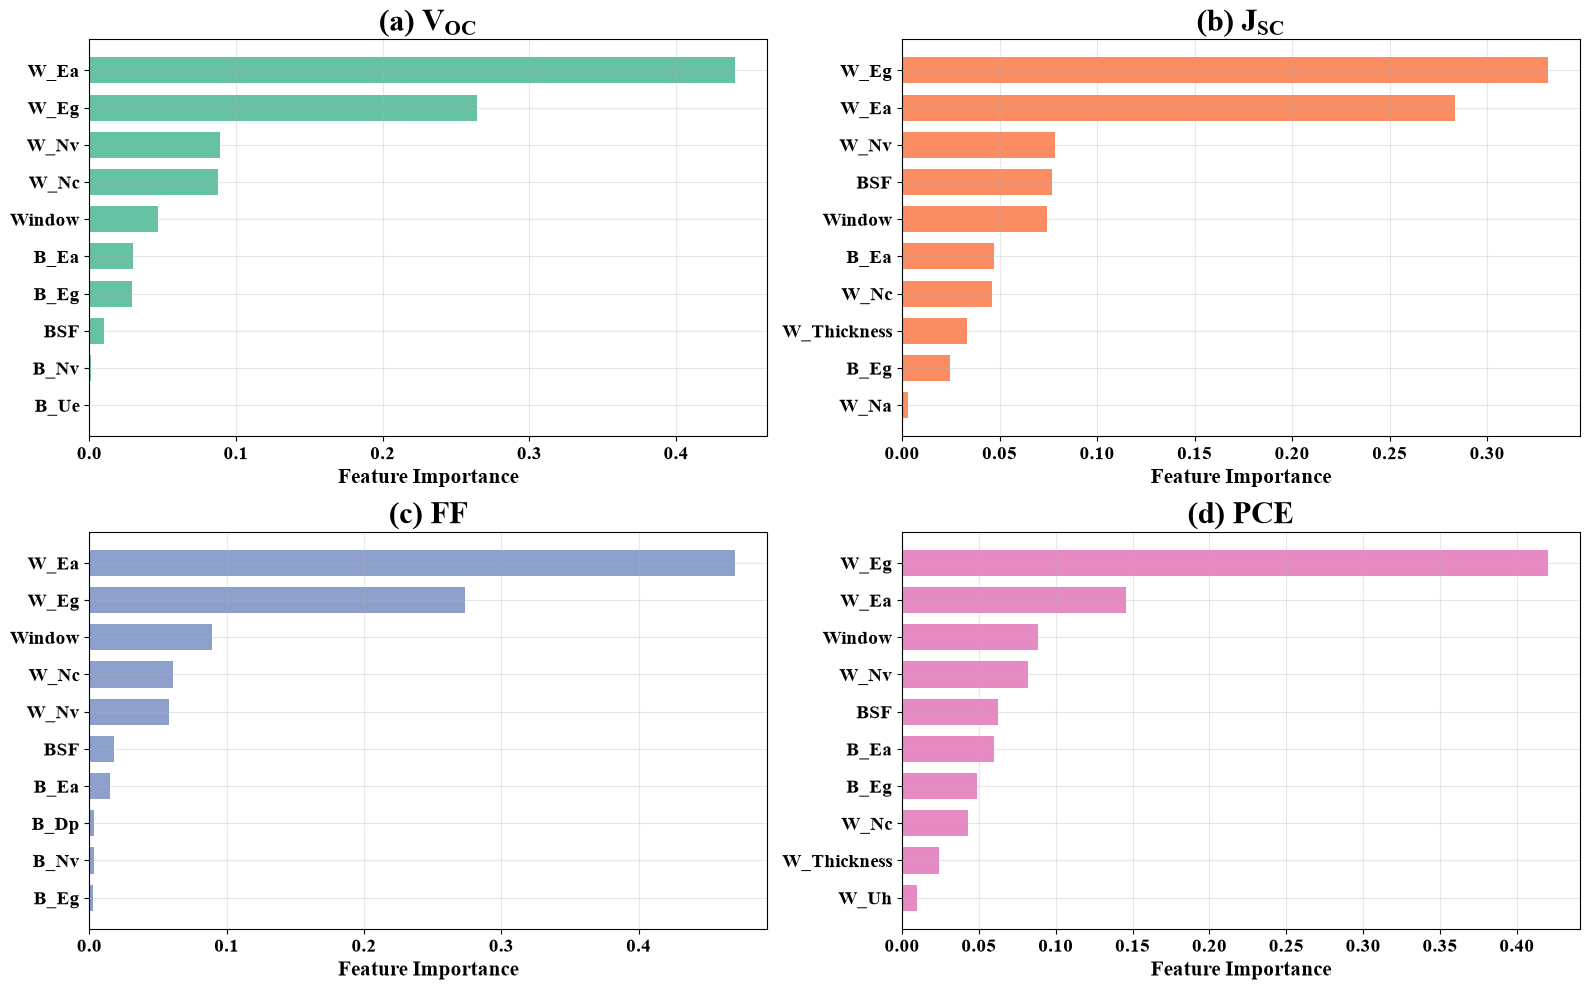

In [73]:
import string
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from xgboost import XGBRegressor

# Set global font weight to bold and family to Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'

# Set math text to also use Times New Roman for bold formatting
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

# Mapping for formatted titles with subscripts
title_mapping = {
    'Voc': r'$\mathbf{V_{OC}}$',
    'Jsc': r'$\mathbf{J_{SC}}$',
    'FF':  r'$\mathbf{FF}$',
    'PCE': r'$\mathbf{PCE}$',
}

output_columns = ['Voc', 'Jsc', 'FF', 'PCE']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

colors = sns.color_palette("Set2", 6)

for i, output in enumerate(output_columns):
    y_output = y_train[output]

    model = XGBRegressor(learning_rate=0.1, max_depth=3, n_estimators=300, random_state=42)
    model.fit(X_train, y_output)

    feature_importance = model.feature_importances_
    sorted_idx = np.argsort(feature_importance)[-10:]

    axes[i].barh(X_train.columns[sorted_idx], feature_importance[sorted_idx],
                 height=0.7, color=colors[i])
    axes[i].set_xlabel('Feature Importance', size=15, fontweight='bold')

    # Panel letter + mapped title, e.g. "(a) Voc"
    panel_letter = string.ascii_lowercase[i]
    axes[i].set_title(rf'({panel_letter}) {title_mapping[output]}', size=22, fontweight='bold')

    axes[i].tick_params(axis='both', labelsize=14)
    for label in axes[i].get_xticklabels() + axes[i].get_yticklabels():
        label.set_fontweight('bold')

    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('XGB_Feature_importance_CB_VB.png', dpi=500)
plt.show()

In [62]:
df.columns

Index(['Structure', 'Window', 'W_Thickness', 'W_Eg', 'W_Ea', 'W_Dp', 'W_Nc',
       'W_Nv', 'W_Ue', 'W_Uh', 'W_Na', 'W_dd', 'A_Thickness', 'A_Eg', 'A_Ea',
       'A_Dp', 'A_Nc', 'A_Nv', 'A_Ue', 'A_Uh', 'A_Na', 'A_dd', 'BSF',
       'B_Thickness', 'B_Eg', 'B_Ea', 'B_Dp', 'B_Nc', 'B_Nv', 'B_Ue', 'B_Uh',
       'B_Na', 'B_dd', 'Voc', 'Jsc', 'FF', 'PCE'],
      dtype='str')

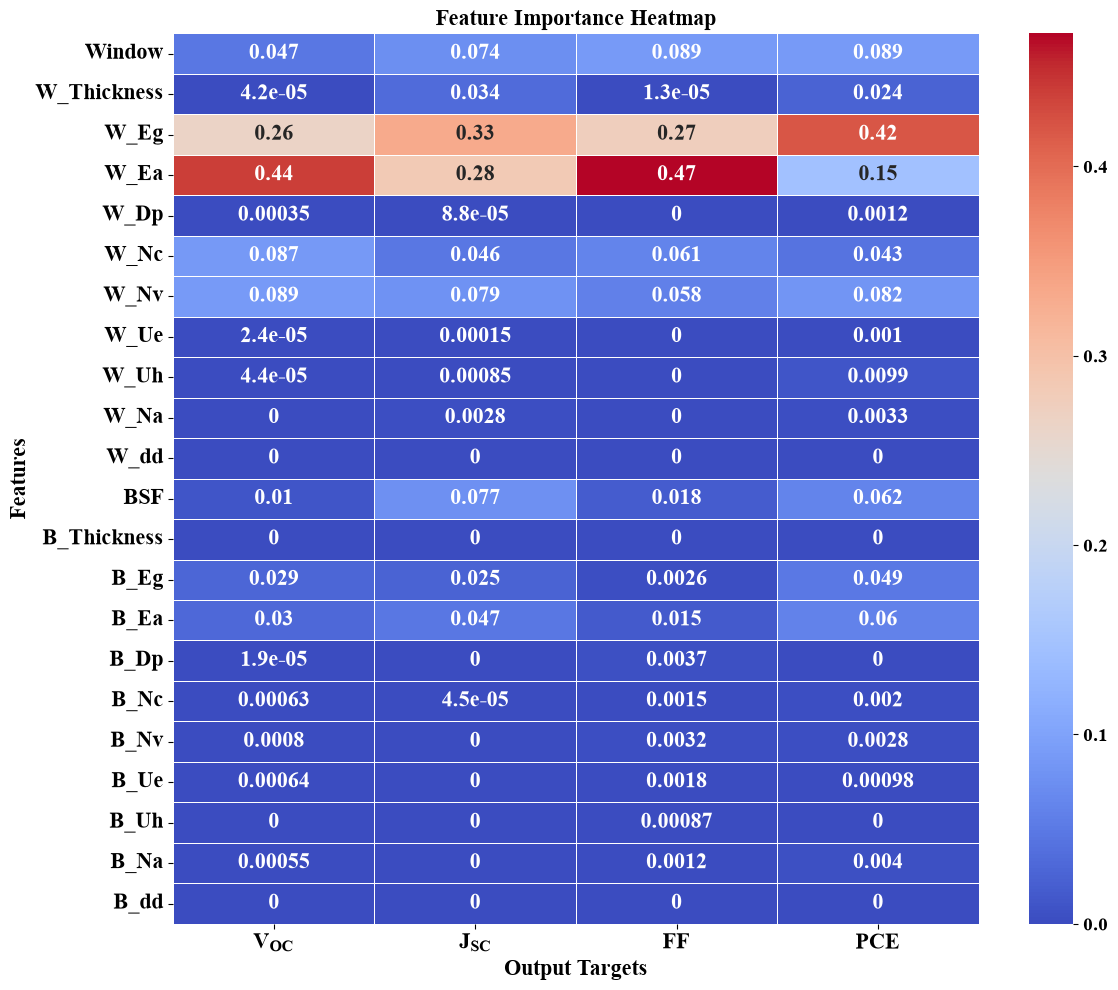

In [63]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from xgboost import XGBRegressor

# Mapping for formatted titles with subscripts (using LaTeX for bold+subscript)
title_mapping = {
    'Voc': r'$\mathbf{V_{OC}}$',
    'Jsc': r'$\mathbf{J_{SC}}$',
    'FF': r'$\mathbf{FF}$',
    'PCE': r'$\mathbf{PCE}$',
    # 'R': r'$\mathbf{R}$',
    # 'D*': r'$\mathbf{D^*}$'
}

# List of output variables
output_columns = ['Voc', 'Jsc', 'FF', 'PCE']

# Features to remove from the plot
remove_features = ['A_Thickness', 'A_Eg', 'A_Ea',
       'A_Dp', 'A_Nc', 'A_Nv', 'A_Ue', 'A_Uh', 'A_Na', 'A_dd']

# Initialize matrix
feature_importance_matrix = np.zeros((X_train.shape[1], len(output_columns)))

# Calculate feature importance
for i, output in enumerate(output_columns):

    y_output = y_train[output]

    model = XGBRegressor(
            learning_rate =0.1, max_depth= 3, n_estimators= 300, random_state= 42    )

    model.fit(X_train, y_output)

    feature_importance = model.feature_importances_

    feature_importance_matrix[:, i] = feature_importance


# Convert to DataFrame for easier filtering
import pandas as pd
# Use the mapped titles for the columns
importance_df = pd.DataFrame(feature_importance_matrix,
                             index=X_train.columns,
                             columns=[title_mapping[col] for col in output_columns])

# Remove unwanted features
importance_df = importance_df.drop(remove_features)

# Plot heatmap
plt.figure(figsize=(12,10))
sns.heatmap(importance_df,
            annot=True,
            cmap='coolwarm',
            cbar=True,
            linewidths=0.5,
            annot_kws={"size":16, "weight":"bold"}  # inner numbers size
            )

plt.title('Feature Importance Heatmap', fontsize=16, weight='bold')
plt.xlabel('Output Targets', fontsize=16, weight='bold')
plt.ylabel('Features', fontsize=16, weight='bold')
plt.xticks(fontsize=16, weight='bold')
plt.yticks(fontsize=16, weight='bold')

plt.tight_layout()
# plt.savefig('XGB_Heatmap_CB_VB.png', dpi=500, bbox_inches='tight')
plt.show()

# ACT v s Pred


In [66]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.ticker import MaxNLocator
import os

# --- Global font: Times New Roman, bold ---
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['axes.titleweight'] = 'bold'
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.bf'] = 'Times New Roman:bold'

targets = ['Voc', 'Jsc', 'FF', 'PCE']
model_name = 'XGB'

display_map = {
    'Voc': r'$\mathbf{V_{OC}}$ (V)',
    'Jsc': r'$\mathbf{J_{SC}}$ (mA/cm²)',
    'FF':  r'$\mathbf{FF}$ (%)',
    'PCE': r'$\mathbf{PCE}$ (%)',
}

output_path = r'E:\Research\Abir bhai\mail pappu bhai\Data\ML\act-vs-pred'
os.makedirs(output_path, exist_ok=True)

for target in targets:
    # --- Collect data directly from the previous XGBoost cell ---
    y_tr_true = y_train[target].values
    y_te_true = y_test[target].values
    y_tr_pred = xgb_train_predictions[target]
    y_te_pred = xgb_test_predictions[target]

    rmse_train = metrics_dict_XGB_train[target]['RMSE']
    rmse_test  = metrics_dict_XGB[target]['RMSE']

    fig, ax = plt.subplots(figsize=(6, 5))

    ax.scatter(y_tr_true, y_tr_pred, color='steelblue', label='Train', alpha=0.6, s=50)
    ax.scatter(y_te_true, y_te_pred, color='red', label='Test', alpha=0.8, s=50)

    # Perfect prediction line (y = x)
    min_val = min(y_tr_true.min(), y_te_true.min())
    max_val = max(y_tr_true.max(), y_te_true.max())
    ax.plot([min_val, max_val], [min_val, max_val],
            'k--', linewidth=2, label='Perfect Prediction')

    ax.set_title(f'{model_name} | {display_map[target]}\n'
                 f'Train RMSE = {rmse_train:.4f} | Test RMSE = {rmse_test:.4f}',
                 size=16, weight='bold', color='black')
    ax.set_xlabel('True Values', size=14, weight='bold')
    ax.set_ylabel('Predicted Values', size=14, weight='bold')

    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    leg = ax.legend(fontsize=12, loc='upper left')
    for text in leg.get_texts():
        text.set_fontweight('bold')

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    ax.tick_params(axis='both', labelsize=12)

    ax.grid(True, alpha=0.3, linestyle='--', which='both')
    ax.set_facecolor('#f0f8ff')

    plt.tight_layout()
    file_name = f'{target}_ActualVsPredicted.png'
    plt.savefig(os.path.join(output_path, file_name), dpi=500, bbox_inches='tight')
    print(f"✅ Saved: {file_name}")
    plt.close(fig)

print("\n" + "=" * 70)
print(f"✅ All {len(targets)} figures saved successfully!")
print(f"📁 Output Path: {output_path}")
print("=" * 70)
print(f"\n📊 {model_name} RMSE:")
for target in targets:
    print(f"   {target}: Train RMSE = {metrics_dict_XGB_train[target]['RMSE']:.4f} | "
          f"Test RMSE = {metrics_dict_XGB[target]['RMSE']:.4f}")
print("=" * 70)

✅ Saved: Voc_ActualVsPredicted.png
✅ Saved: Jsc_ActualVsPredicted.png
✅ Saved: FF_ActualVsPredicted.png
✅ Saved: PCE_ActualVsPredicted.png

✅ All 4 figures saved successfully!
📁 Output Path: E:\Research\Abir bhai\mail pappu bhai\Data\ML\act-vs-pred

📊 XGB RMSE:
   Voc: Train RMSE = 0.0025 | Test RMSE = 0.0168
   Jsc: Train RMSE = 0.0373 | Test RMSE = 0.2383
   FF: Train RMSE = 0.0647 | Test RMSE = 1.9007
   PCE: Train RMSE = 0.0951 | Test RMSE = 0.4362


In [104]:
# # Use df_original to ensure the target columns are present before dropping
# X = df_original.drop(columns=["Voc", "Jsc", "FF", "PCE"])
# y = df_original[["Voc", "Jsc", "FF", "PCE"]]

# from sklearn.model_selection import learning_curve
# import numpy as np
# import matplotlib.pyplot as plt

# train_sizes, train_scores, test_scores = learning_curve(
#     best_rf, X, y, cv=5, scoring="r2",
#     train_sizes=np.linspace(0.1, 1.0, 10),
#     n_jobs=-1
# )

# plt.plot(train_sizes, train_scores.mean(axis=1), label="Train")
# plt.plot(train_sizes, test_scores.mean(axis=1), label="CV")
# plt.xlabel("Training Size")
# plt.ylabel("R²")
# plt.legend()
# plt.show()

In [105]:
# from xgboost import XGBRegressor
# from sklearn.model_selection import cross_val_score, KFold
# import numpy as np
# import matplotlib.pyplot as plt
# import pandas as pd

# # Ensure y_train is a DataFrame
# y_train_df = pd.DataFrame(y_train, columns=['Voc', 'Jsc', 'FF', 'PCE'])

# # Initialize model
# xgb_reg = XGBRegressor(
#    colsample_bytree=0.8, learning_rate=0.1, max_depth=5, n_estimators=500, subsample=0.8, random_state=42
# )

# # Define 5-fold CV
# kf = KFold(n_splits=5, shuffle=True, random_state=42)

# # Store R² results
# cv_r2_results = {}

# # Loop over each target
# targets = ['Voc', 'Jsc', 'FF', 'PCE']
# for target in targets:
#     print(f"Cross-validating {target} for R²...")
#     scores = cross_val_score(
#         xgb_reg, X_train, y_train_df[target],  # use column by name
#         scoring='r2',
#         cv=kf
#     )
#     cv_r2_results[target] = scores
#     print(f"{target} R² (per fold): {scores}")
#     print(f"{target} R² mean: {scores.mean():.4f}\n")

# # ============================
# # Plot journal-style figure
# # ============================
# # Plot CV R² results - journal style
# plt.figure(figsize=(8,6))

# line_width = 2.5
# marker_size = 10

# for target in targets:
#     plt.plot(
#         list(range(1, kf.get_n_splits()+1)),  # ensure integer x-axis
#         cv_r2_results[target],
#         marker='o',
#         markersize=marker_size,
#         linewidth=line_width,
#         label=target
#     )

# # Journal style fonts
# plt.rcParams.update({'font.family': ['serif']})
# plt.xlabel('Fold', fontsize=16, fontweight='bold', fontfamily='serif')
# plt.ylabel('R² Score', fontsize=16, fontweight='bold', fontfamily='serif')
# plt.title('XGB 5-Fold Cross Validation R² per Target', fontsize=18, fontweight='bold', fontfamily='serif')
# plt.xticks(ticks=range(1, kf.get_n_splits()+1), fontsize=14,fontweight='bold')  # x-axis ticks 1,2,3,4,5
# plt.yticks(fontsize=14,fontweight='bold')
# plt.ylim(0.95, 1.0)  # set y-axis range

# # Legend and grid
# plt.legend(fontsize=14)
# # plt.grid(True, linestyle='--', linewidth=1)
# plt.tick_params(width=2, length=6)

# plt.savefig('XGB 5-Fold Cross Validation R² per Target.png', dpi=500, bbox_inches='tight')
# plt.show()
